Plot the residuals logMdot from color fit to logMdot observed.

11:22
observed here = model fit.

11:23
observed should be the model-fit result we get from the online data.

11:26
We could try (for our logMdot formulae) rotating logMdotcalc to get the same distribution of mass loss rates for the data and the observations.

11:28
Another option - two-color fit to logMdot

11:29
logMdot(fit K-first color) - logMdot(model) vs. other colors and see if that gives a second color to reduce the scatter (edited) 

11:29
A good two-color fit could be widely useful.

11:31
Start with shorter wavelength colors

11:40
For each type, post 3 best combinations.



Plot all of logMdot(K-8.0) - logMdot(Mdot_dust) vs other colors

Other colors? We have 7 wavelengths (J, H, K, 3.6micron, 4.5micron, 5.8micron, and 8.0micron):
    J-H, J-K, J-3.6, J-4.5, J-5.8, J-8.0
    H-K, H-3.6, H-4.5, H-5.8, H-8.0
    K-3.6, K-4.5, K-5.8
    3.6-4.5, 3.6-5.8, 3.6-8.0
    4.5-5.8, 4.5-8.0
    5.8-8.0
We can safely cut half the combinations as they are negatives of each other. We can also skip K-8.0 because that is the 1st color we are using to fit (not much use plotting vs. itself). That means 20 combinations. Multiplying by 4 (composition+mode), we have 80 plots to look through.

In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator
import os

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
#plt.rcParams['figure.facecolor'] = 'w'
#plt.rcParams['figure.edgecolor'] = 'k'

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [4]:
def clear_rows_with_nAn_for_color (RawStarData, band_1_index, band_2_index ):
    band_1_nAn_index = []
    band_2_nAn_index = []
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    band_1_nAn = np.isnan(band_1_data)
    band_2_nAn = np.isnan(band_2_data)
    index_list_1 = np.where(band_1_nAn == True)[0]
    index_list_2 = np.where(band_2_nAn == True)[0]
    full_index_list = np.concatenate((index_list_1, index_list_2))
    full_index_list = np.unique(full_index_list) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (nAn):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def clear_rows_with_color_less_than_value (RawStarData, band_1_index, band_2_index,value=0 ):
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    color = band_1_data - band_2_data
    less_than_value = []
    for i in range (0,len(color)):
        if color[i] < value:
            less_than_value.append(i)
    #print(less_than_value)
    full_index_list = np.unique(less_than_value) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (color<'+str(value)+'):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def calculate_color (band_1, band_2):
    return band_1 - band_2

In [5]:
# Calculates the mass-loss rate from a hyperbolic fit to color
#                  a
#   log Mdot = _________ + c
#              color + b
def calc_mdot_from_color (color_data, a, b, c): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = a/(color_data+b) + c 
    return color_log_mdot

In [6]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [7]:
# First, define function for ODR
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [8]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [9]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [10]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [11]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    return fit_parameters

In [12]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [13]:
np.shape(C0StarData)

(28, 1995)

In [14]:
def sort_xC0(stellar_data): # Function to separate 'extreme' AGB stars from the carbon star population
    '''
    “As in Blum et al. (2006) and Srinivasan et al. (2009), we identify x-AGB stars as those brighter than the 3.6 μm TRGB and 
    with J −[3.6] > 3.1 mag. Some of the most heavily dust-enshrouded x-AGB stars are totally undetected in the near-IR. 
    Therefore, if there is no near-IR detection, but [3.6] − [8] > 0.8 and the star is brighter than the 3.6 μm TRGB, then it is
    also included in the initial list of x-AGB stars.” 
    - Boyer et. al, 2011 https://iopscience.iop.org/article/10.1088/0004-6256/142/4/103/pdf
    '''
    mag_J = stellar_data[JIndex]
    mag_36 = stellar_data[ThreePointSixIndex]
    mag_8 = stellar_data[EightPointZeroIndex]
    cut_line_1 = np.asarray([3.1,3.1])
    line_coords_1 = np.asarray([np.nanmin(mag_36 - mag_8),np.nanmax(mag_36 - mag_8)])
    # Plot 1: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_J - mag_36,s=2)
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Plot 2: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_36,s=2)
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Now, the acutal sorting function
    normal_indices = []
    extreme_indices = []
    for i in range(0,np.shape(stellar_data)[1]): # Iterate over every entry in stellar_data
        if np.isnan(mag_J[i]) == False and np.isnan(mag_36[i]) == False: # If there is an entry for J and [3.6]
            if mag_J[i]-mag_36[i] > 3.1: # Stars bluer than this should be classified as extreme
                extreme_indices.append(i)
            else: # Otherwise they are not
                normal_indices.append(i)
        elif np.isnan(mag_36[i]) == False and np.isnan(mag_8[i]) == False: # If there is an entry for [3.6] and [8.0]
            if mag_36[i]-mag_8[i]>0.8:
                extreme_indices.append(i)
            else:
                normal_indices.append(i)
        else:
            normal_indices.append(i)
            print('Non-sortable star found at index ',i,'. Assumed to not be extreme.')
    
    norm_array = []
    extr_array = []
    for i in range(0, len(normal_indices)):
        norm_array.append(np.transpose(stellar_data)[normal_indices[i]])
    np_norm_array = np.asarray(norm_array)
    for i in range(0, len(extreme_indices)):
        extr_array.append(np.transpose(stellar_data)[extreme_indices[i]])
    np_extr_array = np.asarray(extr_array)
    
    mag_J_n = np.transpose(np_norm_array)[JIndex]
    mag_36_n = np.transpose(np_norm_array)[ThreePointSixIndex]
    mag_8_n = np.transpose(np_norm_array)[EightPointZeroIndex]
    mag_J_x = np.transpose(np_extr_array)[JIndex]
    mag_36_x = np.transpose(np_extr_array)[ThreePointSixIndex]
    mag_8_x = np.transpose(np_extr_array)[EightPointZeroIndex]
    
    # Plot 3: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_J_n - mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_J_x - mag_36_x,s=2,label='C0x')
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    plot.legend()
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Plot 4: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_36_x,s=2,label='C0x')
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plot.legend()
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    return np.transpose(np_norm_array), np.transpose(np_extr_array)

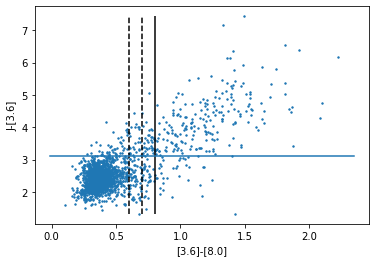

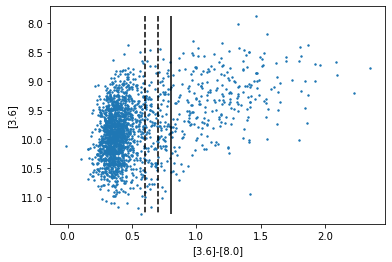

Non-sortable star found at index  0 . Assumed to not be extreme.
Non-sortable star found at index  227 . Assumed to not be extreme.
Non-sortable star found at index  243 . Assumed to not be extreme.
Non-sortable star found at index  250 . Assumed to not be extreme.
Non-sortable star found at index  748 . Assumed to not be extreme.
Non-sortable star found at index  917 . Assumed to not be extreme.
Non-sortable star found at index  1035 . Assumed to not be extreme.
Non-sortable star found at index  1189 . Assumed to not be extreme.
Non-sortable star found at index  1331 . Assumed to not be extreme.
Non-sortable star found at index  1339 . Assumed to not be extreme.
Non-sortable star found at index  1385 . Assumed to not be extreme.
Non-sortable star found at index  1597 . Assumed to not be extreme.


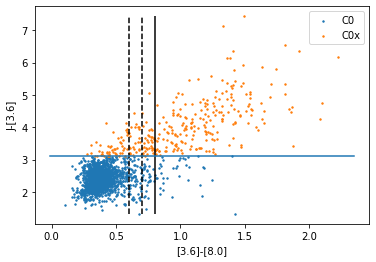

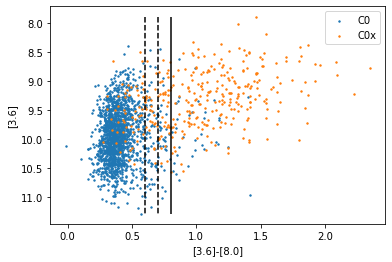

In [15]:
C0StarData_n,C0StarData_x  = sort_xC0(C0StarData)

In [16]:

print('Calculating colors for M0 stars...')
M0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M0StarData, KIndex, EightPointZeroIndex)
M0_color_K_minus_80 = calculate_color (M0_reduced_for_K_minus_80[KIndex],M0_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for M1 stars...')
M1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M1StarData, KIndex, EightPointZeroIndex)
M1_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
M1_color_K_minus_80 = calculate_color (M1_reduced_for_K_minus_80[KIndex],M1_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0 stars...')
C0_n_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_n, KIndex, EightPointZeroIndex)
C0_n_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_n_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_n_color_K_minus_80 = calculate_color (C0_n_reduced_for_K_minus_80[KIndex],C0_n_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0x stars...')
C0_x_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_x, KIndex, EightPointZeroIndex)
C0_x_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_x_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_x_color_K_minus_80 = calculate_color (C0_x_reduced_for_K_minus_80[KIndex],C0_x_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C1 stars...')
C1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C1StarData, KIndex, EightPointZeroIndex)
C1_color_K_minus_80 = calculate_color (C1_reduced_for_K_minus_80[KIndex],C1_reduced_for_K_minus_80[EightPointZeroIndex])

Calculating colors for M0 stars...
Stars removed (nAn): 9
Calculating colors for M1 stars...
Stars removed (nAn): 6
Stars removed (color<0): 1
Calculating colors for C0 stars...
Stars removed (nAn): 22
Stars removed (color<0): 1
Calculating colors for C0x stars...
Stars removed (nAn): 26
Stars removed (color<0): 0
Calculating colors for C1 stars...
Stars removed (nAn): 2


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:27: DeprecationWarning: using a non-integer array as obj in delete will result in an error in the future


In [17]:
# Functions to sort a list
def examine_index_third(elem): 
    # Sorting Key. Will sort a list based on the specified index hard coded here.
    return elem[tauIndex]

def sort_star_data_third(DataToSort):
    TransposedArray=np.transpose(DataToSort)
    TempList=TransposedArray.tolist()
    TempList=sorted(TempList,key = operator.itemgetter(1)) # use 2 because we index from 0
    return np.transpose(np.asarray(TempList))

def RangeSelect (DataToTrim, LowerBound, UpperBound ):
    return np.transpose(np.transpose(sort_star_data_third(DataToTrim))[LowerBound:UpperBound])

In [18]:
# Save folder: Mdot_resid_v_color
def plot_mdot_resids_vs_color (star_data, band_1_ind, band_2_ind, mdot_color_coeffs, comp_plus_mode = '', save_fig = False, save_folder = '', less_than_value_color_1 = -np.inf, less_than_value_color_2 = -np.inf):
    # first, we will need to trim the data sets so they are the same size after eliminating possible nAn entries.
    reduced_for_K_minus_eight = clear_rows_with_nAn_for_color(star_data, KIndex, EightPointZeroIndex) # Hard code this color because we have already settled on that as our first to examine. Could be changed if necessary.
    if less_than_value_color_1 != -np.inf:
        reduced_for_K_minus_eight = clear_rows_with_color_less_than_value(reduced_for_K_minus_eight, KIndex, EightPointZeroIndex, value=less_than_value_color_1 )
    reduced_for_chosen_color = clear_rows_with_nAn_for_color(reduced_for_K_minus_eight, band_1_ind, band_2_ind)
    if less_than_value_color_2 != -np.inf:
        reduced_for_chosen_color = clear_rows_with_color_less_than_value(reduced_for_chosen_color, band_1_ind, band_2_ind, value=less_than_value_color_2 )
    color_1 = calculate_color (reduced_for_chosen_color[KIndex],reduced_for_chosen_color[EightPointZeroIndex]) # Hard code as K-[8.0]
    color_2 = calculate_color (reduced_for_chosen_color[band_1_ind],reduced_for_chosen_color[band_2_ind])
    a = mdot_color_coeffs[0]
    b = mdot_color_coeffs[1]
    c = mdot_color_coeffs[2]
    mdot_from_color = calc_mdot_from_color(color_1, a, b, c)
    mdot_from_model = np.log10(reduced_for_chosen_color[MdotIndex])
    mdot_residual = mdot_from_color - mdot_from_model
    #print(mdot_from_model)
    chisqparams = chi_sq_fit_2d (color_2, mdot_residual )
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.nanmin(color_2),np.nanmax(color_2)])
    print(fit_parameters)
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'Color'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.scatter(color_2,mdot_residual,s=2, label='Data')
    plot.plot(fit_x,fit_y, color='orange',label = fit_label)
    plot.title(comp_plus_mode)
    # (J, H, K, 3.6micron, 4.5micron, 5.8micron, and 8.0micron)
    if band_1_ind == JIndex:
        band_1_str = 'J'
    if band_1_ind == HIndex:
        band_1_str = 'H'
    if band_1_ind == KIndex:
        band_1_str = 'K'
    if band_1_ind == ThreePointSixIndex:
        band_1_str = '[3.6]'
    if band_1_ind == FourPointFiveIndex:
        band_1_str = '[4.5]'
    if band_1_ind == FivePointEightIndex:
        band_1_str = '[5.8]'
    if band_1_ind == EightPointZeroIndex:
        band_1_str = '[8.0]'
    if band_2_ind == JIndex:
        band_2_str = 'K'
    if band_2_ind == HIndex:
        band_2_str = 'H'
    if band_2_ind == KIndex:
        band_2_str = 'K'
    if band_2_ind == ThreePointSixIndex:
        band_2_str = '[3.6]'
    if band_2_ind == FourPointFiveIndex:
        band_2_str = '[4.5]'
    if band_2_ind == FivePointEightIndex:
        band_2_str = '[5.8]'
    if band_2_ind == EightPointZeroIndex:
        band_2_str = '[8.0]'
    plot.xlabel('Color: ' + band_1_str + '-' + band_2_str)
    plot.ylabel('logMdot_color - logMdot_GRAMS_model')
    plot.legend()
    if save_fig == True:
        plot_name = save_folder + '/' + band_1_str + '-' + band_2_str + '_'+ comp_plus_mode
        plot.savefig(plot_name+'.png')
        #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    
    return reduced_for_chosen_color

In [19]:
def hyperbolic_func (C, P0, P1, P2):
    # logMdot = a/(C + b) + c
    return ((P0/(C+P1)))+P2 

def hyperbolic_func_pls_lin (C, P0, P1, P2, P3):
    # logMdot = a/(K - [8.0] + b) - α col + (c - β) => logMdot = P0/(C1 + {1}) - P2*C2 + P3
    C0 = np.asarray(C[0])
    C1 = np.asarray(C[1])
    return ((P0/(C0+P1)))-P2*C1 + P3 

In [1]:
def fit_to_hyperbolic (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0, z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],initial_guess=[]):
    if len (initial_guess) >0:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata,p0=initial_guess)
    else:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata)
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            #print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
            plot.close()
        else:
            plot.show()
            plot.close()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
            plot.close()
        else:
            plot.show()
            plot.close()
    return [fit_parameters[0], fit_parameters[1], fit_parameters[2]]
    

In [2]:
M0_color_coeffs = fit_to_hyperbolic(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex])
M1_color_coeffs = fit_to_hyperbolic(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex])
C0_color_coeffs = fit_to_hyperbolic(C0_n_color_K_minus_80,np.log10(C0_n_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_n_reduced_for_K_minus_80[tauIndex])
C1_color_coeffs = fit_to_hyperbolic(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=3, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex])
C0x_color_coeffs = fit_to_hyperbolic(C0_x_color_K_minus_80,np.log10(C0_x_reduced_for_K_minus_80[MdotIndex]), plot_title='C0x', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_x_reduced_for_K_minus_80[tauIndex],initial_guess = C0_color_coeffs )

NameError: name 'M0_color_K_minus_80' is not defined

Other colors? We have 7 wavelengths (J, H, K, 3.6micron, 4.5micron, 5.8micron, and 8.0micron):
    J-H, J-K, J-3.6, J-4.5, J-5.8, J-8.0
    H-K, H-3.6, H-4.5, H-5.8, H-8.0
    K-3.6, K-4.5, K-5.8
    3.6-4.5, 3.6-5.8, 3.6-8.0
    4.5-5.8, 4.5-8.0
    5.8-8.0

In [22]:
## J-...
# J-H
plot_mdot_resids_vs_color(M0StarData, JIndex , HIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , HIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_JMinH = plot_mdot_resids_vs_color(C0StarData_n, JIndex , HIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , HIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , HIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-K
M0_2Color_Data_JMinK = plot_mdot_resids_vs_color(M0StarData, JIndex , KIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , KIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_JMinK = plot_mdot_resids_vs_color(C0StarData_n, JIndex , KIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , KIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , KIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-3.6
plot_mdot_resids_vs_color(M0StarData, JIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-4.5
plot_mdot_resids_vs_color(M0StarData, JIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-5.8
plot_mdot_resids_vs_color(M0StarData, JIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-8.0
plot_mdot_resids_vs_color(M0StarData, JIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## H-...
# H-K/K-H
plot_mdot_resids_vs_color(M0StarData, HIndex , KIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , KIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , KIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , KIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , KIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')

plot_mdot_resids_vs_color(M0StarData, KIndex , HIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
M1_2Color_Data_KMinH = plot_mdot_resids_vs_color(M1StarData, KIndex , HIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_KMinH = plot_mdot_resids_vs_color(C0StarData_n, KIndex , HIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , HIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , HIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-3.6
plot_mdot_resids_vs_color(M0StarData, HIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-4.5
plot_mdot_resids_vs_color(M0StarData, HIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-5.8
plot_mdot_resids_vs_color(M0StarData, HIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-8.0
plot_mdot_resids_vs_color(M0StarData, HIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## K-...
# K-3.6
plot_mdot_resids_vs_color(M0StarData, KIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# K-4.5
plot_mdot_resids_vs_color(M0StarData, KIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# K-5.8
plot_mdot_resids_vs_color(M0StarData, KIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 3.6-...
# 3.6-4.5
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 3.6-5.8
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 3.6-8.0
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 4.5-...
# 4.5-5.8
plot_mdot_resids_vs_color(M0StarData, FourPointFiveIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FourPointFiveIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FourPointFiveIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FourPointFiveIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FourPointFiveIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 4.5-8.0
plot_mdot_resids_vs_color(M0StarData, FourPointFiveIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FourPointFiveIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FourPointFiveIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FourPointFiveIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FourPointFiveIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 5.8-...
# 5.8-8.0
plot_mdot_resids_vs_color(M0StarData, FivePointEightIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FivePointEightIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FivePointEightIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FivePointEightIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FivePointEightIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')

Stars removed (nAn): 9
Stars removed (nAn): 7
[ 1.09678832 -1.23631523]
Stars removed (nAn): 6
Stars removed (nAn): 5
[ 0.90687057 -0.97933759]
Stars removed (nAn): 22
Stars removed (nAn): 5
[ 0.57856053 -0.50286086]
Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.11028319 -0.0731353 ]
Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.13767259 -0.12196657]
Stars removed (nAn): 9
Stars removed (nAn): 6
[ 1.02630312 -0.86897712]
Stars removed (nAn): 6
Stars removed (nAn): 4
[ 0.98249243 -0.80353044]
Stars removed (nAn): 22
Stars removed (nAn): 4
[ 0.45017318 -0.25227651]
Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.07524173 -0.02856184]
Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.13841472 -0.08078404]
Stars removed (nAn): 9
Stars removed (nAn): 6
[ 0.56570897 -0.39092219]
Stars removed (nAn): 6
Stars removed (nAn): 13
[ 0.51536663 -0.35438205]
Stars removed (nAn): 22
Stars removed (nAn): 14
[ 0.2786601  -0.11536603]
Stars removed (nAn): 26
Stars removed (nAn): 1
[-0.029409

array([[1.16850000e+04, 1.16900000e+04, 1.17010000e+04, ...,
        1.48910000e+04, 1.49120000e+04, 1.50560000e+04],
       [1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
        1.00000000e+00, 1.00000000e+00, 1.00000000e+00],
       [3.80000000e-11, 2.50000000e-11, 1.10000000e-10, ...,
        1.30000000e-09, 1.10000000e-09, 1.90000000e-08],
       ...,
       [3.26590006e+03, 3.39319873e+03, 3.19802733e+03, ...,
        2.86146380e+03, 2.83433158e+03, 2.99400008e+03],
       [1.38000000e+01, 1.04400000e+01, 1.38200000e+01, ...,
        4.35900000e+01, 1.54270000e+02, 3.42700000e+01],
       [6.00000000e-03, 6.00000000e-03, 4.00000000e-03, ...,
        3.00000000e-01, 3.00000000e-01, 4.00000000e-01]])

The fits for residual vs H-K and J-K have the most distinctive trends, so we'll use that data to provide a second variable to fit with.

In [23]:
def fit_to_hyperbolic_pls_lin (xdata, ydata, save_fig = 0, plot_title = '', x_label_0='',x_label_1 = '',y_label='', save_folder = '', z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],initial_guess=[]):
    # logMdot = a/(K - [8.0] + b) + c
    # xdata should be an array of color data for a set of stars; the zeroth column should be for your primary fit and the
    # second column should be your data used for correction
    if len (initial_guess) >0:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata[0], ydata,p0=initial_guess) # For this version
        # we will use our regular hyperbolic fit and then simply subtract the residual correction
    else:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata[0], ydata)
    # Now calculate residuals, and subtract those off our initial fit for an algebraic 2-color correction    
    a = fit_parameters[0]
    b = fit_parameters[1]
    c = fit_parameters[2]
    mdot_from_color = calc_mdot_from_color(xdata[0], a, b, c)
    mdot_from_model = ydata
    #print('Debug: mdot_from_color=',mdot_from_color)
    #print('Debug: mdot_from_model=',mdot_from_model)
    mdot_residual = mdot_from_color - mdot_from_model
    #print('Debug: xdata[1]=',xdata[1])
    #print('Debug: mdot_residual=',mdot_residual)
    residual_parameters, residual_r2 = chi_sq_fit_2d (xdata[1],mdot_residual) # Do a simple chi squared fit of our chosen second color vs. our residual mDot
    
    fit_left_C0 = np.min(xdata[0])
    fit_left_C1 = np.min(xdata[1])
    fit_right_C0 = np.max(xdata[0])
    fit_right_C1 = np.max(xdata[1])
    #print(fit_left,fit_right)
    fit_data_0 = [fit_left_C0]
    new_elem_0 = fit_left_C0 + np.abs((fit_right_C0-fit_left_C0))/100
    while len(fit_data_0)<100:
        fit_data_0.append(new_elem_0)
        new_elem_0 = new_elem_0 + np.abs((fit_right_C0-fit_left_C0))/100
    fit_data_1 = [fit_left_C1]
    new_elem_1 = fit_left_C1 + np.abs((fit_right_C1-fit_left_C1))/100
    while len(fit_data_1)<100:
        fit_data_1.append(new_elem_1)
        new_elem_1 = new_elem_1 + np.abs((fit_right_C1-fit_left_C1))/100
    #print(fit_data)
    fit_data = [fit_data_0,fit_data_1]
    fit_curve = hyperbolic_func (fit_data_0, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    fit_y = hyperbolic_func (xdata[0], fit_parameters[0], fit_parameters[1], fit_parameters[2]) - (residual_parameters[1]*xdata[1] + residual_parameters[0])
    # Plot 1: logMdot vs Main Color
    if len(z_color_by_data)>0: 
        plot.scatter(xdata[0], ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
    elif manual_data_bin_tau >0:
        zdata = np.asarray(z_data_to_sort)
        data_to_sort = np.transpose(np.asarray([xdata[0], ydata, zdata])) # Stack our data so we can associate data points with each other
        a = data_to_sort
        ind=np.argsort(a[:,-1])
        sorted_data=np.transpose(np.asarray(a[ind]))
            #print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
        bin_size = len(data_to_sort)//manual_data_bin_tau
        bin_bottom = 0
        bin_top = bin_size
        #print('len(data_to_sort):',len(data_to_sort))
        i=0
        while i < manual_data_bin_tau:
            if i ==0: # When on first bin
                working_x=sorted_data[0][:bin_top]
                working_y=sorted_data[1][:bin_top]
                data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            elif i == manual_data_bin_tau-1: # If we are on the last bin
                working_x=sorted_data[0][bin_bottom:]
                working_y=sorted_data[1][bin_bottom:]
                data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            else: # We are on some intermediate bin
                working_x=sorted_data[0][bin_bottom:bin_top]
                working_y=sorted_data[1][bin_bottom:bin_top]
                #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            bin_bottom = bin_bottom+bin_size
            #print('bin_bottom:',bin_bottom)
            bin_top = bin_top + bin_size
            #print('bin_top:',bin_top)
            i = i + 1
    else:
        plot.scatter(xdata[0], ydata, label='Data',s=2)
    #print('Debug: fit_data[0]=',fit_data[0])
    #print('Debug: fit_curve=',fit_curve)
    plot.plot(fit_data[0],fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
    plot.title(plot_title+'; Color 2 = '+x_label_1)
    plot.legend()
    plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
    plot.xlabel(x_label_0)
    plot.ylabel(y_label)
    if save_fig !=0:
        plot.savefig(save_folder+'/'+y_label+'_vs_'+x_label_0+'.png')
        plot.savefig(save_folder+'/'+y_label+'_vs_'+x_label_0+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 2: logMdot_GRAMS vs logMdot_color
    plot.scatter(fit_y,ydata,label='Data',s=2)
    plot.title(plot_title+'; Color 2 = '+x_label_1)
    #print(np.min(ydata),np.min(fit_y))
    bottom_left = np.min([np.min(ydata),np.min(fit_y)])-0.1
    top_right = np.max([np.max(ydata),np.max(fit_y)])+0.1
    fit_parameters_2, r2_parameters_2 = chi_sq_fit_2d (fit_y,ydata)
    fit_line = np.asarray([fit_parameters_2[1]*bottom_left + fit_parameters_2[0], fit_parameters_2[1]*top_right + fit_parameters_2[0]])
    OneToOneData=[bottom_left,top_right]
    plot.plot(OneToOneData, fit_line,marker='.',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(fit_parameters_2),color='orange')
    plot.plot(OneToOneData, OneToOneData,color='k',marker='.')
    #print(bottom_left,top_right)
    plot.xlim(bottom_left, top_right)
    plot.ylim(bottom_left, top_right)
    plot.xlabel('logMdot_2color_Alg')
    plot.ylabel('logMdot_GRAMS')
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+'logMdot_GRAMS'+'_vs_'+'logMdot_2color_Alg'+'.png')
        plot.savefig(save_folder+'/'+'logMdot_GRAMS'+'_vs_'+'logMdot_2color_Alg'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 3: Histogram of Residuals. We want to know which has the smallest range for the C0 Stars.
    hist_data = fit_y-ydata # New Residual, after applying 2nd color correction
    n, bins, patches = plot.hist(hist_data,bins=10) # Histogram of residual logMdot_color-logMdot_GRAMS
    print('n:',n)
    print('np.max(n):',np.max(n))
    standard_dev = hist_data.std()
    print('Standard Dev.', standard_dev)
    mean = hist_data.mean()
    print('mean:',mean)
    hist_left=np.min(hist_data)
    hist_right=np.max(hist_data)
    
    normal_sample = [hist_left]
    new_elem_norm_samp = hist_left + np.abs((hist_right-hist_left))/100
    while len(normal_sample)<100:
        normal_sample.append(new_elem_norm_samp)
        new_elem_norm_samp = new_elem_norm_samp + np.abs((hist_right-hist_left))/100
    #print(normal_sample)
    # f(x) = 1/(sigma*sqrt(2*pi))*exp(-1/2*((x-mean)/sigma)**2)
    normal_func = (1/(standard_dev*np.sqrt(2*np.pi)) )*np.exp(-0.5*((normal_sample-mean)/standard_dev)**2)
    normal_func = np.max(n)/np.max(normal_func)*normal_func
    #print(normal_func)
    plot.plot(normal_sample,normal_func,ls='--',marker='',label='normal: std=%5.3f, mean=%5.3f' % tuple([standard_dev,mean]))
    plot.xlabel('logMdot_2color_Alg-logMdot_GRAMS')
    plot.ylabel('N')
    plot.title(plot_title+'; Color 2 = '+x_label_1)
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+'Hist_logMdot_2color_Alg-logMdot_GRAMS'+'.png')
        plot.savefig(save_folder+'/'+'Hist_logMdot_2color_Alg-logMdot_GRAMS'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 4: Residual vs Color 1
    plot.scatter(xdata[0],hist_data,s=2)
    plot.title(plot_title+'; Color 2 = '+x_label_1)
    plot.ylabel('logMdot_2color_Alg-logMdot_GRAMS')
    plot.xlabel(x_label_0)
    residual_parameters_plot_4, residual_r2_plot_4 = chi_sq_fit_2d (xdata[0],hist_data)
    #print('np.nanmin(xdata[0]):',np.nanmin(xdata[0]))
    #print('np.nanmax(xdata[0]):',np.nanmax(xdata[0]))
    lr_bounds = np.asarray([np.nanmin(xdata[0]),np.nanmax(xdata[0])])
    tb_values = residual_parameters_plot_4[1]*lr_bounds+residual_parameters_plot_4[0]
    #print('tb_values:',tb_values)
    plot.plot(lr_bounds,tb_values,marker='',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(residual_parameters_plot_4),color='orange')
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+'Residual_vs_Color1'+'.png')
        plot.savefig(save_folder+'/'+'Residual_vs_Color1'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
    
    
    # Plot 5: Residual vs Color 2
    plot.scatter(xdata[1],hist_data,s=2)
    plot.title(plot_title+'; Color 1 = '+x_label_0)
    plot.ylabel('logMdot_2color_Alg-logMdot_GRAMS')
    plot.xlabel(x_label_1)
    residual_parameters_plot_5, residual_r2_plot_5 = chi_sq_fit_2d (xdata[1],hist_data)
    lr_bounds = np.asarray([np.nanmin(xdata[1]),np.nanmax(xdata[1])])
    tb_values = residual_parameters_plot_5[1]*lr_bounds+residual_parameters_plot_5[0]
    plot.plot(lr_bounds,tb_values,marker='',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(residual_parameters_plot_5),color='orange')
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+'Residual_vs_Color2'+'.png')
        plot.savefig(save_folder+'/'+'Residual_vs_Color2'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
    
    return [fit_parameters[0], fit_parameters[1], fit_parameters[2], residual_parameters[0], residual_parameters[1]]
    

In [24]:
# Data: M0_2Color_Data_JMinK, M1_2Color_Data_KMinH, C0_2Color_Data_JMinH, C0_2Color_Data_JMinK, C0_2Color_Data_KMinH
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg'
save_value = 1
# M0
M0_K_Min_Eight = calculate_color(M0_2Color_Data_JMinK[KIndex],M0_2Color_Data_JMinK[EightPointZeroIndex])
M0_J_Min_K = calculate_color(M0_2Color_Data_JMinK[JIndex],M0_2Color_Data_JMinK[KIndex])
M0_Coeff_2color = fit_to_hyperbolic_pls_lin(np.asarray([M0_K_Min_Eight,M0_J_Min_K]),np.log10(M0_2Color_Data_JMinK[MdotIndex]), plot_title='M0', x_label_0='K-[8.0]', x_label_1='J-K', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_2Color_Data_JMinK[tauIndex], save_fig = save_value,save_folder=Directory)
# M1
M1_K_Min_Eight = calculate_color(M1_2Color_Data_KMinH[KIndex],M1_2Color_Data_KMinH[EightPointZeroIndex])
M1_K_Min_H = calculate_color(M1_2Color_Data_KMinH[KIndex],M1_2Color_Data_KMinH[HIndex])
M1_Coeff_2color = fit_to_hyperbolic_pls_lin(np.asarray([M1_K_Min_Eight,M1_K_Min_H]),np.log10(M1_2Color_Data_KMinH[MdotIndex]), plot_title='M1', x_label_0='K-[8.0]', x_label_1='K-H', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_2Color_Data_KMinH[tauIndex], save_fig = save_value,save_folder=Directory)
# C0
C0_K_Min_Eight_for_J_Min_H = calculate_color(C0_2Color_Data_JMinH[KIndex],C0_2Color_Data_JMinH[EightPointZeroIndex])
C0_J_Min_H = calculate_color(C0_2Color_Data_JMinH[JIndex],C0_2Color_Data_JMinH[HIndex])
fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_J_Min_H,C0_J_Min_H]),np.log10(C0_2Color_Data_JMinH[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='J-H', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_2Color_Data_JMinH[tauIndex], save_fig = save_value,save_folder=Directory)

C0_K_Min_Eight_for_J_Min_K = calculate_color(C0_2Color_Data_JMinK[KIndex],C0_2Color_Data_JMinK[EightPointZeroIndex])
C0_J_Min_K = calculate_color(C0_2Color_Data_JMinK[JIndex],C0_2Color_Data_JMinK[KIndex])
C0_Coeff_2color = fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_J_Min_K,C0_J_Min_K]),np.log10(C0_2Color_Data_JMinK[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='J-K', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_2Color_Data_JMinK[tauIndex], save_fig = save_value,save_folder=Directory)

C0_K_Min_Eight_for_K_Min_H = calculate_color(C0_2Color_Data_KMinH[KIndex],C0_2Color_Data_KMinH[EightPointZeroIndex])
C0_K_Min_H = calculate_color(C0_2Color_Data_KMinH[KIndex],C0_2Color_Data_KMinH[HIndex])
fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_K_Min_H,C0_K_Min_H]),np.log10(C0_2Color_Data_KMinH[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='K-H', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_2Color_Data_KMinH[tauIndex], save_fig = save_value,save_folder=Directory)


n: [1.000e+00 3.000e+00 1.100e+01 1.490e+02 1.049e+03 6.250e+02 8.200e+01
 1.000e+01 5.000e+00 1.000e+00]
np.max(n): 1049.0
Standard Dev. 0.20779507290727067
mean: 5.18409924721664e-16
n: [  1.   0.   0.   4.  31. 186. 921. 812. 177.  21.]
np.max(n): 921.0
Standard Dev. 0.24369236023815
mean: 2.0131494139046034e-16
n: [  2.   6.  17.  64. 245. 565. 506. 192.  25.   5.]
np.max(n): 565.0
Standard Dev. 0.12450630753235731
mean: -3.821296212600416e-18
n: [  2.   7.  12.  58. 198. 533. 557. 221.  35.   5.]
np.max(n): 557.0
Standard Dev. 0.1242414925680199
mean: 3.0278809762504267e-16
n: [  3.   5.  15.  60. 208. 564. 525. 198.  45.   5.]
np.max(n): 564.0
Standard Dev. 0.12483875906063265
mean: -8.183462097974127e-18


[-4.456436736882068,
 1.0605410425624648,
 -4.4938562415774745,
 0.26454177824495173,
 0.41663315111992344]

In [25]:
np.shape(M0_2Color_Data_JMinK)

(30, 1936)

In [26]:
# Calculates the mass-loss rate from a hyperbolic fit to color
#                  a
#   log Mdot = _________ + c
#              color + b
def calc_mdot_from_color (color_data, coeff_data): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = coeff_data[0]/(color_data[0]+coeff_data[1]) + coeff_data[2] - (coeff_data[3]*color_data[1] + coeff_data[4])
    return color_log_mdot

In [27]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [28]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [29]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [30]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [31]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    return fit_parameters

In [32]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [33]:
def full_parameter_analysis (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot_logmdot_vs_parameter (stellar_data_mdot, stellar_data_x, title=plot_label, parameter_label=stellar_data_xlabel,save_folder = save_folder,save_fig = save_fig)
    #plot.scatter(stellar_data_x,stellar_data_mdot,s=2)
    #fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    #fit_y = Betas[0] + Betas[1]*fit_x
    #plot.plot(fit_x,fit_y,color='orange')
    #plot.xlabel(stellar_data_xlabel)
    #plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #plot.show()
    #plot.close()
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)

In [34]:
M0_color_Mdot = calc_mdot_from_color ([M0_K_Min_Eight,M0_J_Min_K], M0_Coeff_2color)
M1_color_Mdot = calc_mdot_from_color ([M1_K_Min_Eight,M1_K_Min_H], M1_Coeff_2color)
C0_color_Mdot = calc_mdot_from_color ([C0_K_Min_Eight_for_J_Min_K,C0_J_Min_K], C0_Coeff_2color)

M0:

 Fit: logMdot= -0.30009491006460104 *x+ -6.462924324330863


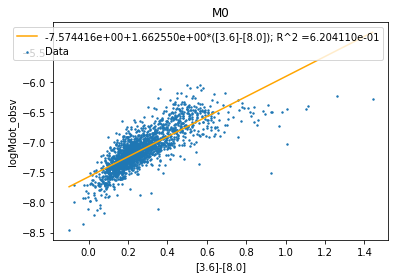

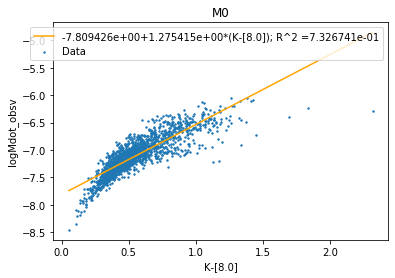


M1:

 Fit: logMdot= 1.0125166579859068 *x+ -10.133895081848756


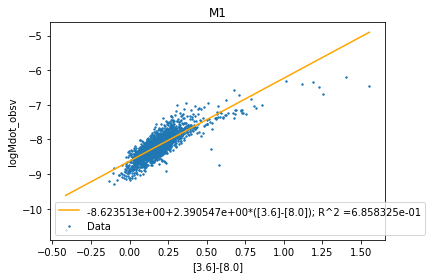

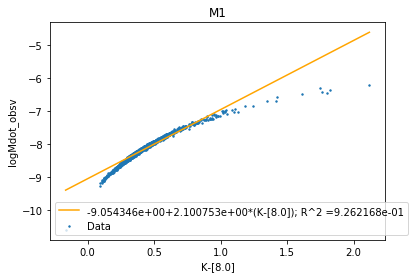


C0

 Fit: logMdot= 0.10443818436170382 *x+ -7.454301983779128


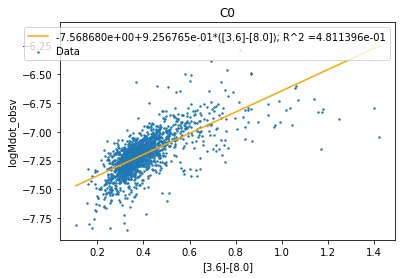

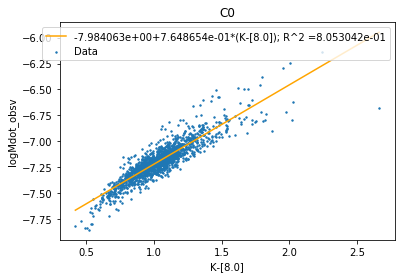

In [35]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/logP'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[PIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(P)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_KMinH[PIndex]), M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(P)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[PIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(P)', plot_label='C0', save_fig = 1, save_folder=Directory)


M0:

 Fit: logMdot= -0.6694475632811817 *x+ -4.7598363514844575


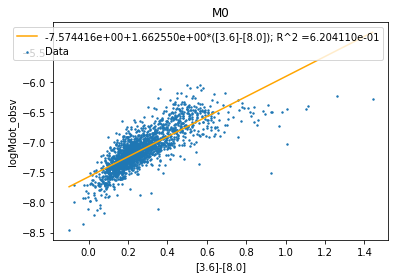

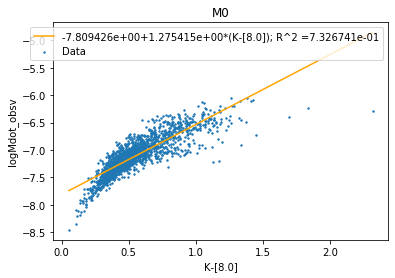


M1:

 Fit: logMdot= 0.4764510966560701 *x+ -9.873589926669514


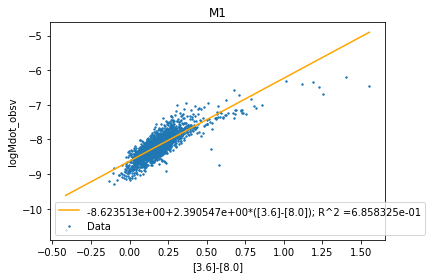

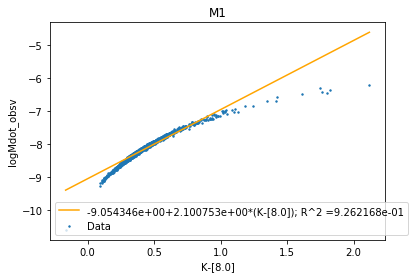


C0

 Fit: logMdot= 0.05340085854180328 *x+ -7.396022369580564


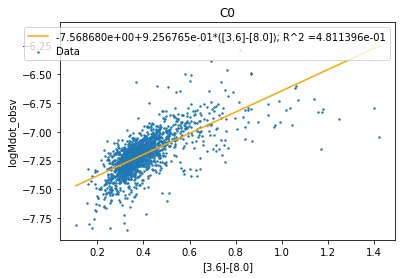

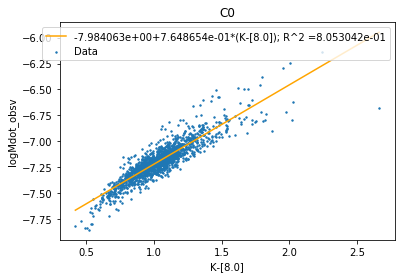

In [36]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/logL'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[LIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_KMinH[LIndex]), M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(L)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[LIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L)', plot_label='C0', save_fig = 1, save_folder=Directory)


M0:

 Fit: logMdot= -1.051710088387623 *x+ -4.820314743704086


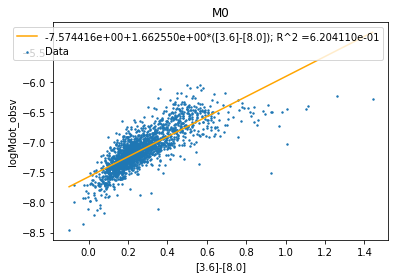

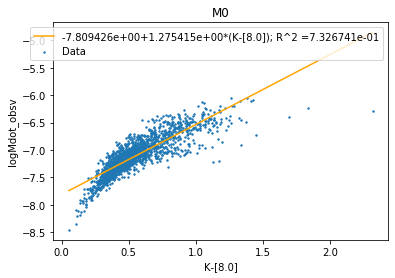


M1:

 Fit: logMdot= 0.9669599112011106 *x+ -10.322362447695788


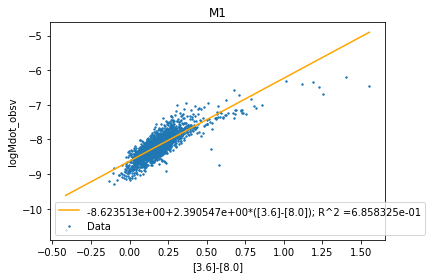

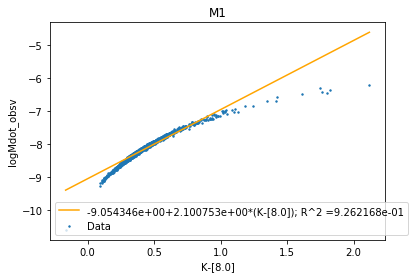


C0

 Fit: logMdot= 0.12029028365451291 *x+ -7.4833235029292435


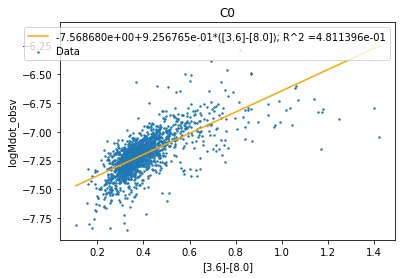

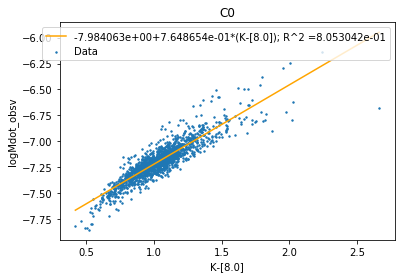

In [37]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/logR'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[RIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(R)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_KMinH[RIndex]), M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(R)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[RIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(R)', plot_label='C0', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -1.126713108042378 *x+ -7.107350572845759


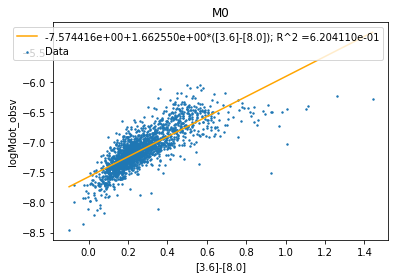

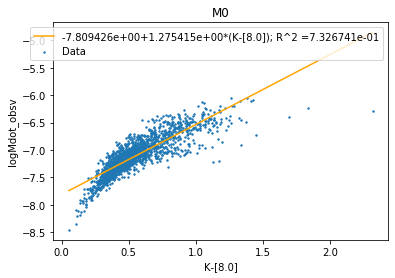


M1:

 Fit: logMdot= 0.18653754057111463 *x+ -8.167825667273792


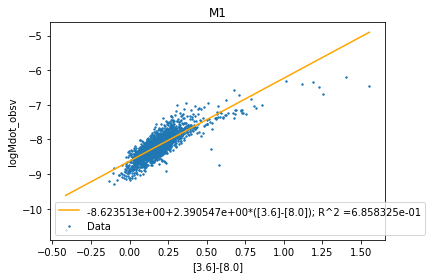

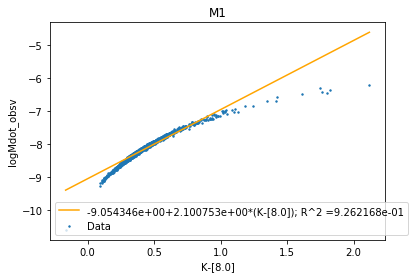


C0

 Fit: logMdot= 0.04827514239011918 *x+ -7.2013815516382405


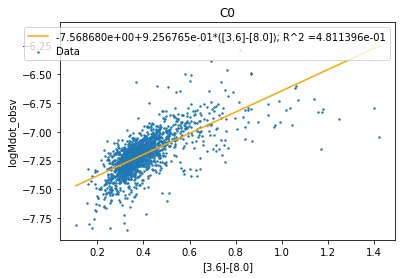

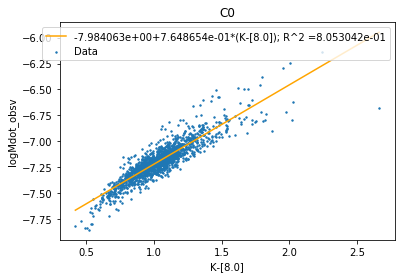

In [38]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/logM'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[MIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_KMinH[MIndex]), M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(M)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[MIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M)', plot_label='C0', save_fig = 1, save_folder=Directory)


In [39]:
M0_logPE = calc_PE_scale(M0_2Color_Data_JMinK)
M1_logPE = calc_PE_scale(M1_2Color_Data_KMinH)
C0_logPE = calc_PE_scale(C0_2Color_Data_JMinK)

M0_logg = calc_g_scale(M0_2Color_Data_JMinK)
M1_logg = calc_g_scale(M1_2Color_Data_KMinH)
C0_logg = calc_g_scale(C0_2Color_Data_JMinK)

M0_logLP = calc_lum_pressure_scale(M0_2Color_Data_JMinK)
M1_logLP = calc_lum_pressure_scale(M1_2Color_Data_KMinH)
C0_logLP = calc_lum_pressure_scale(C0_2Color_Data_JMinK)

M0_logCL = calc_core_lum_param(M0_2Color_Data_JMinK)
M1_logCL = calc_core_lum_param(M1_2Color_Data_KMinH)
C0_logCL = calc_core_lum_param(C0_2Color_Data_JMinK)


 Fit: logMdot= -1.024587295932797 *x+ -9.350533499993158


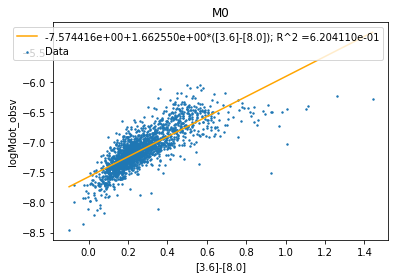

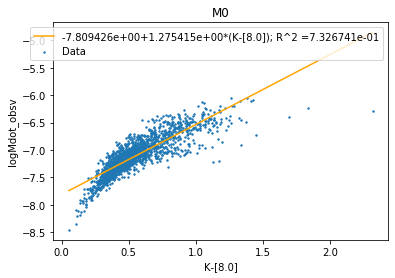


 Fit: logMdot= -2.069486118665477 *x+ -12.766719574859232


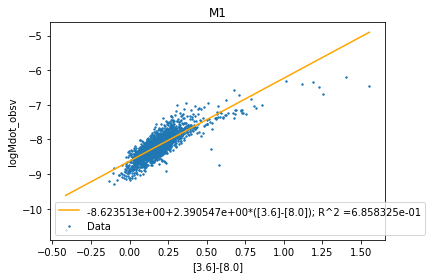

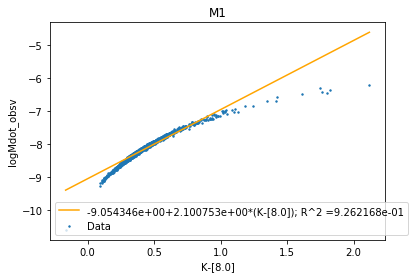


 Fit: logMdot= -0.02838054430004075 *x+ -7.255935579548427


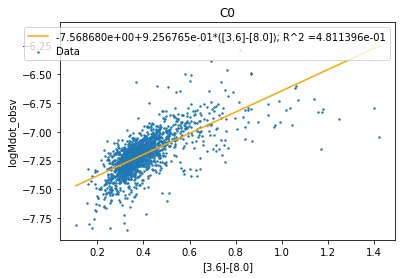

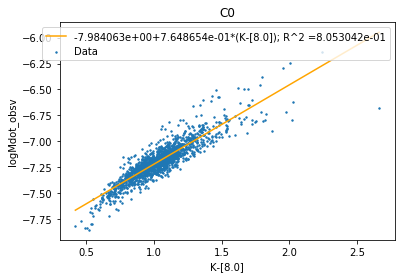

In [40]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/log(M/R)'
full_parameter_analysis (M0_logPE, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logPE, M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logPE, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)


 Fit: logMdot= 0.10787238785557338 *x+ -6.6508471470898165


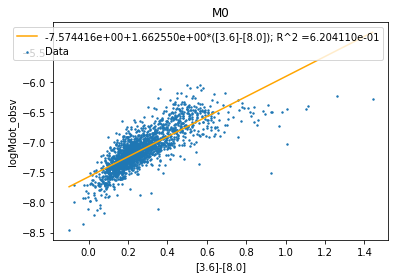

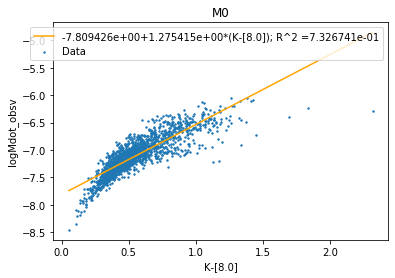


 Fit: logMdot= -0.9915534452096559 *x+ -12.581250505947311


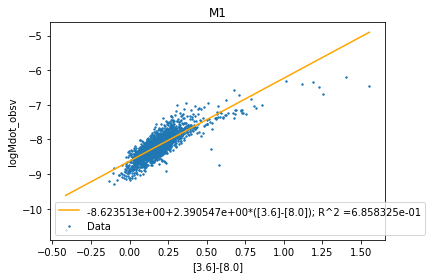

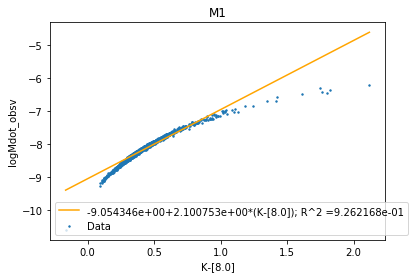


 Fit: logMdot= -0.10799781510275865 *x+ -7.694883928724134


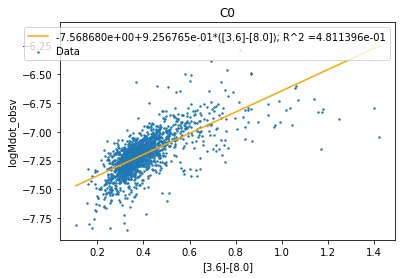

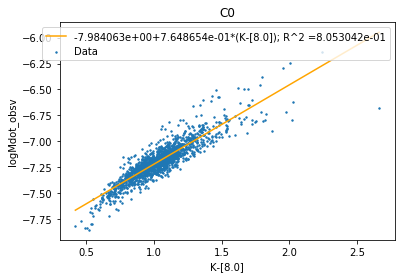

In [41]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/log(M/R^2)'
full_parameter_analysis (M0_logg, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logg, M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(M/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logg, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)



 Fit: logMdot= -0.7257152711921853 *x+ -7.737200623531998


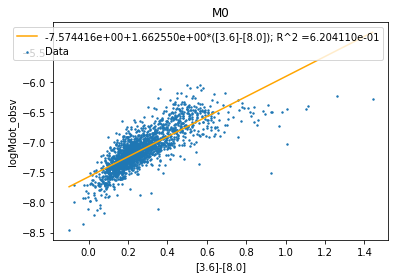

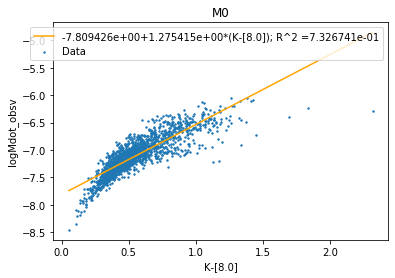


 Fit: logMdot= -4.1836733340187715 *x+ -11.832026633574293


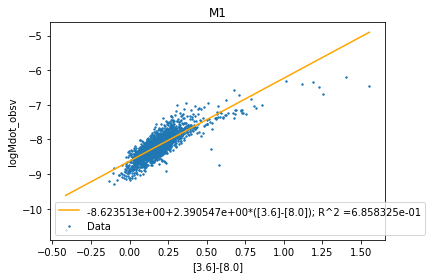

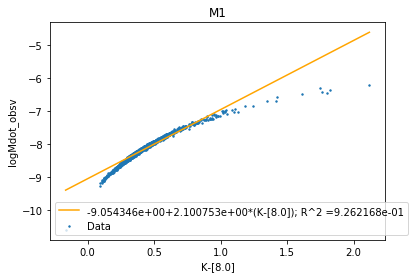


 Fit: logMdot= -0.1600179107615412 *x+ -7.3564225123486615


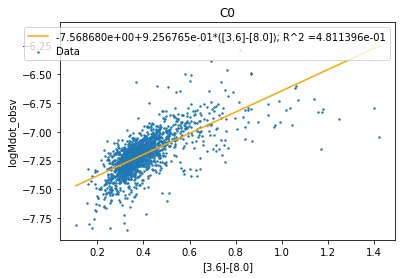

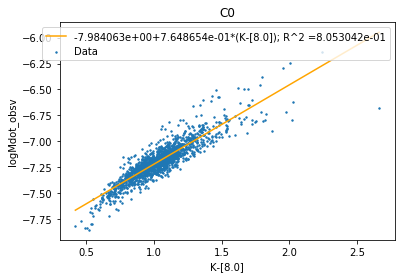

In [42]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/log(L/R^2)'
full_parameter_analysis (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logLP, M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(L/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)



 Fit: logMdot= -0.3020762334889294 *x+ -6.05968181587422


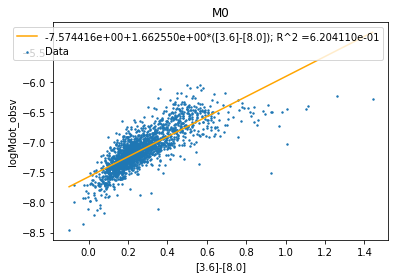

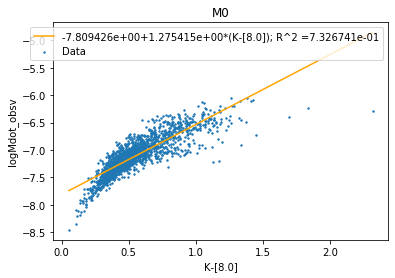


 Fit: logMdot= 1.2664078603315418 *x+ -12.695439466781362


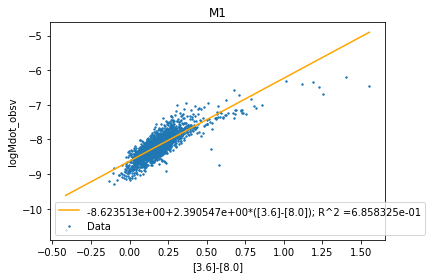

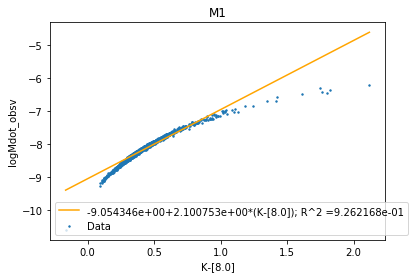


 Fit: logMdot= 0.15268593047628506 *x+ -7.746369089229803


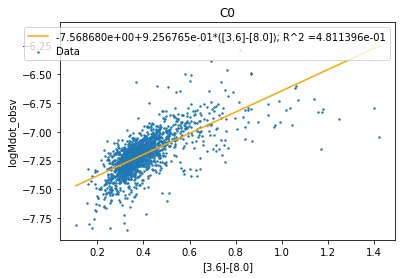

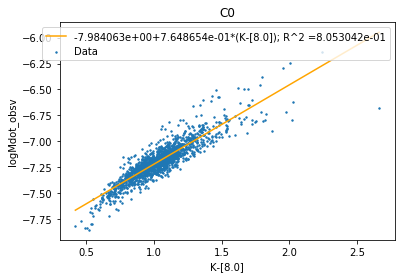

In [43]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/log(L/M)'
full_parameter_analysis (M0_logCL, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L/M)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logCL, M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(L/M)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logCL, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L/M)', plot_label='C0', save_fig = 1, save_folder=Directory)


In [44]:
def PE_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    Correction_betas = plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)')
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*logCL)
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    print('\n Corrected Fit: logMdot=', Betas[1],'*log(M/R)+',Correction_betas[1],'log(L/M)+',Betas[0]-Correction_betas[0])
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label = 'Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    fit_label = str(Betas[1])[:6]+'*log(M/R)+'+str(Correction_betas[1])[:6]+'log(L/M)+'+str(Betas[0]-Correction_betas[0])[:6]+'; R^2 ='+ str(chisqfit_returns[1])[0:6]
    plot.plot(fit_x,fit_y,color='orange',label = fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(M/R)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)


 Initial Fit: logMdot= -1.024587295932797 *x+ -9.350533499993158


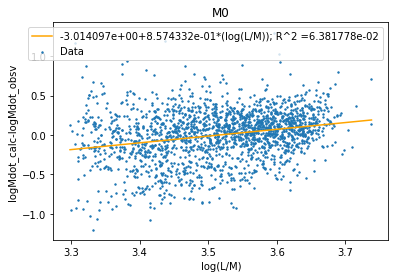


 Corrected Fit: logMdot= -0.41958987781550905 *log(M/R)+ 0.8574331744860776 log(L/M)+ -5.020272041228761


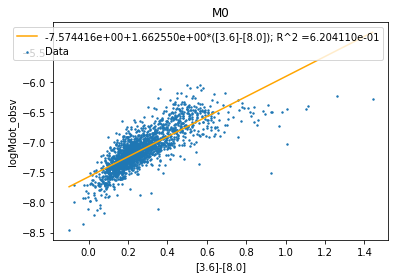

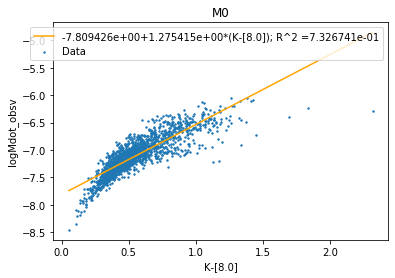




 Initial Fit: logMdot= -2.069486118665477 *x+ -12.766719574859232


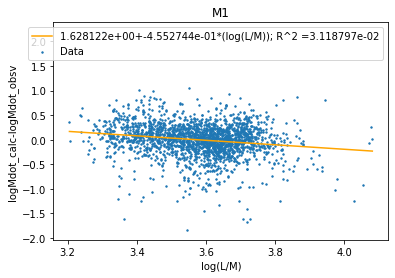


 Corrected Fit: logMdot= -2.5481992320210662 *log(M/R)+ -0.45527444797263233 log(L/M)+ -15.458941538594246


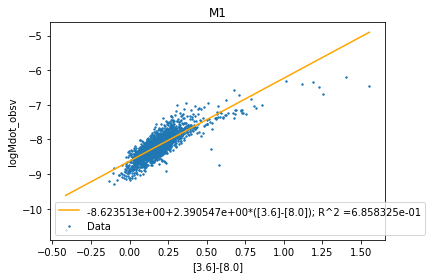

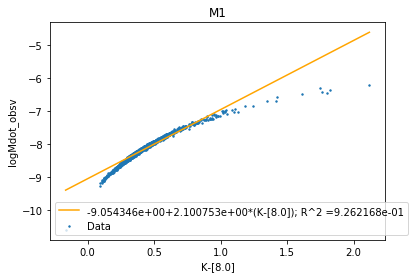




 Initial Fit: logMdot= -0.02838054430004075 *x+ -7.255935579548427


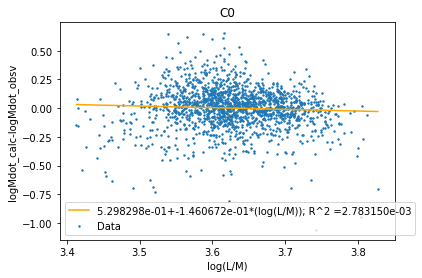


 Corrected Fit: logMdot= -0.06495769035901106 *log(M/R)+ -0.14606715673956647 log(L/M)+ -7.867481930058564


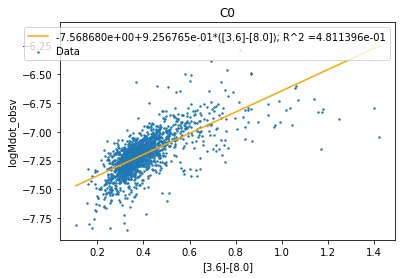

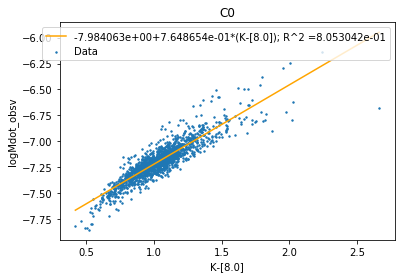

In [45]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/ExtendedAnalyses/log(MdivR)'
PE_minus_resid (M0_logPE, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
PE_minus_resid (M1_logPE, M1_color_Mdot, M1_2Color_Data_KMinH, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
PE_minus_resid (C0_logPE, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)

In [46]:
def T_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, fed_index, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    if fed_index == RIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(R)')
    elif fed_index == LIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(L)')
    elif fed_index == PIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(P)')
    elif fed_index == MIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(M)')
    
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*np.log10(full_stellar_data[fed_index]))
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    if fed_index == RIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(R)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(R)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == LIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(L)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(L)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == PIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(P)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(P)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == MIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(M)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(M)+'+str(Betas[0]-Correction_betas[0])[:6]
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label='Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    plot.plot(fit_x,fit_y,color='orange',label=fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(L/R^2)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)', save_fig = 1, save_folder=Directory)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    #print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label, save_fig = 1, save_folder=Directory)


 Initial Fit: logMdot= -0.7257152711921853 *x+ -7.737200623531998


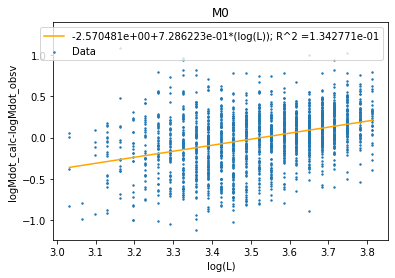


 Corrected Fit: logMdot= 0.5599509309587108 *log(L/R^2)+ 0.7286223117698843 log(L)+ -4.076054678883612


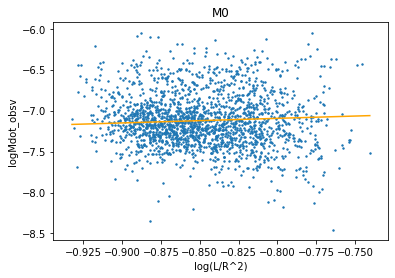

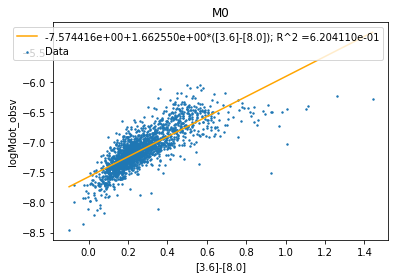

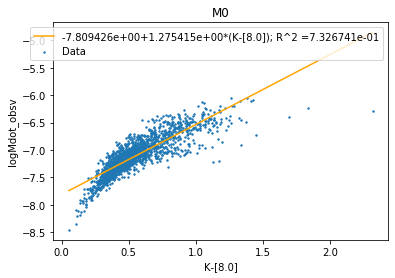

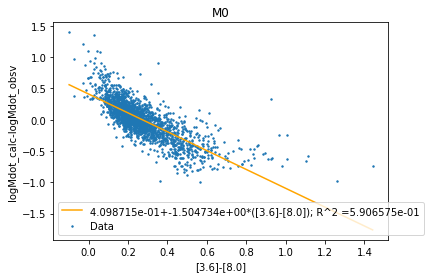

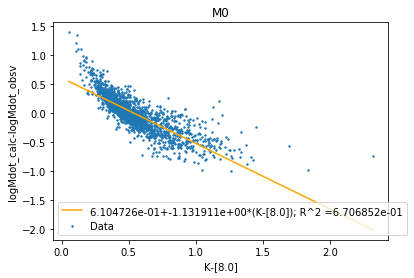


 Initial Fit: logMdot= -4.1836733340187715 *x+ -11.832026633574293


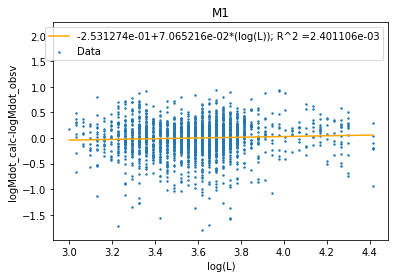


 Corrected Fit: logMdot= -3.9275507757796797 *log(L/R^2)+ 0.07065216404749777 log(L)+ -11.354503233099864


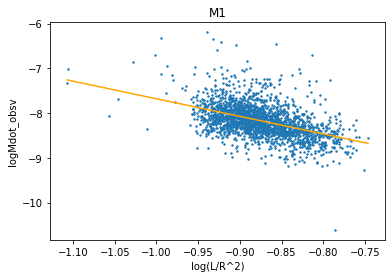

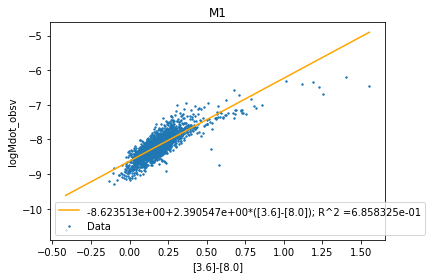

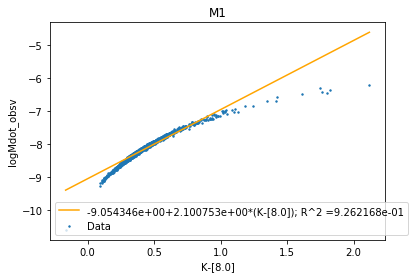

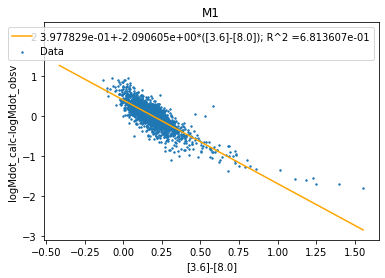

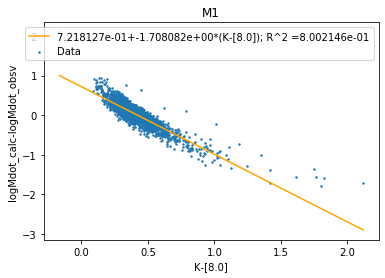


 Initial Fit: logMdot= -0.1600179107615412 *x+ -7.3564225123486615


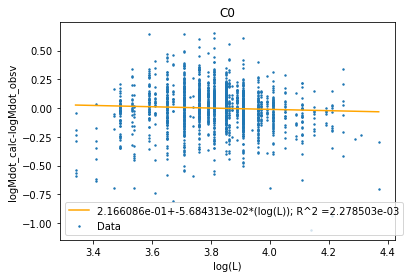


 Corrected Fit: logMdot= -0.13063735019745218 *log(L/R^2)+ -0.056843126414397004 log(L)+ -7.542939360874941


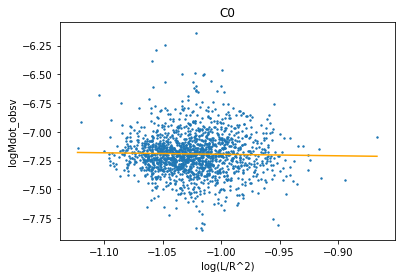

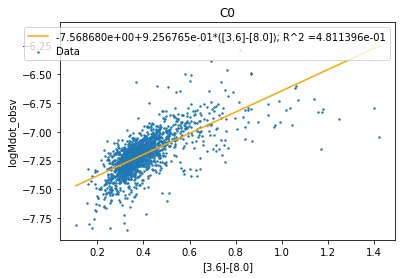

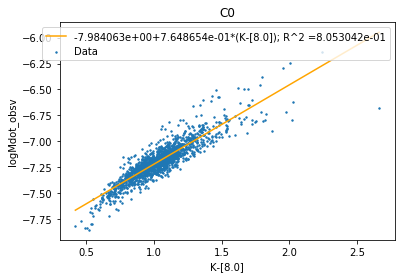

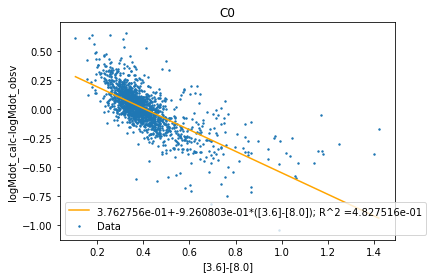

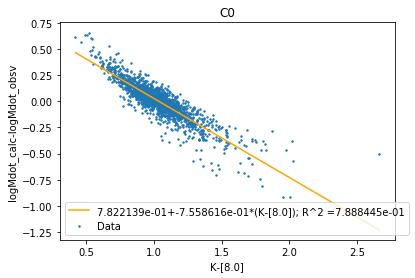

In [47]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/ExtendedAnalyses/log(LdivR^2)/subtract_logL'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_KMinH, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')


 Initial Fit: logMdot= -0.7257152711921853 *x+ -7.737200623531998


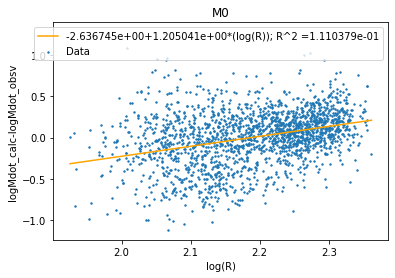


 Corrected Fit: logMdot= 0.939962409960058 *log(L/R^2)+ 1.2050408015704641 log(R)+ -3.687417570376785


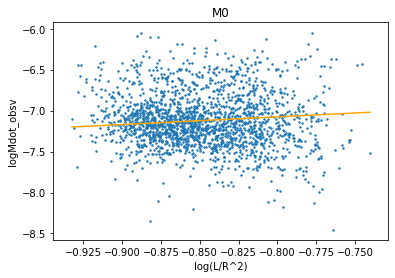

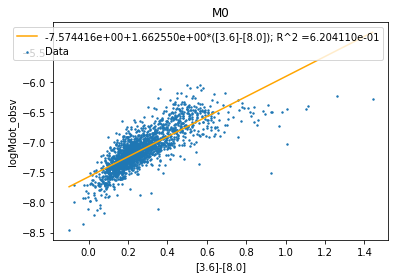

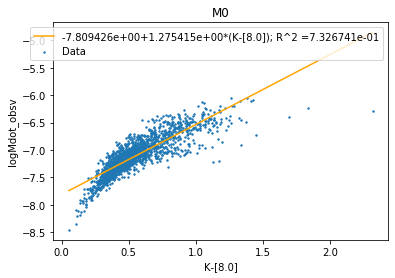

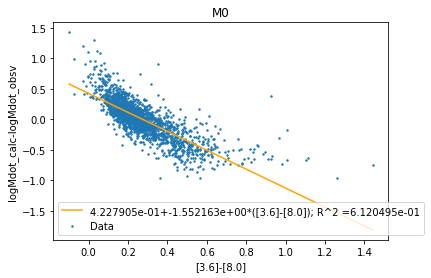

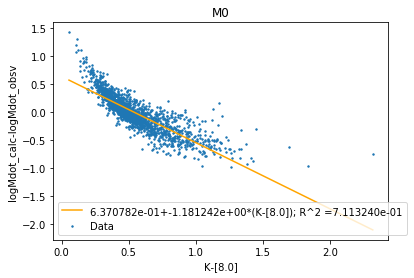


 Initial Fit: logMdot= -4.1836733340187715 *x+ -11.832026633574293


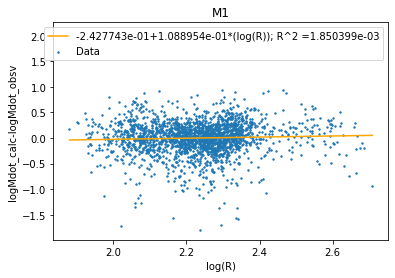


 Corrected Fit: logMdot= -3.931846279117523 *log(L/R^2)+ 0.1088953654063777 log(R)+ -11.36861976538698


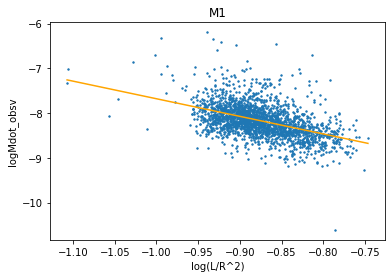

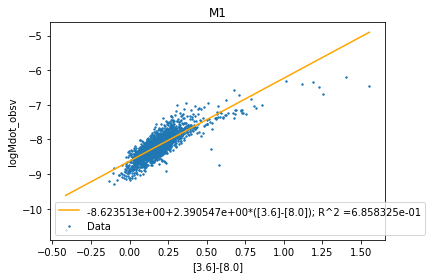

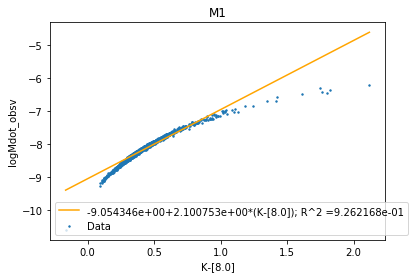

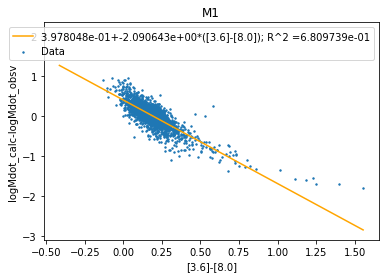

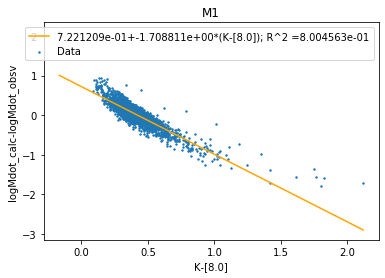


 Initial Fit: logMdot= -0.1600179107615412 *x+ -7.3564225123486615


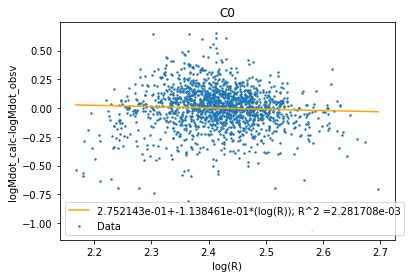


 Corrected Fit: logMdot= -0.1875190968387055 *log(L/R^2)+ -0.11384612823514093 log(R)+ -7.659803712711374


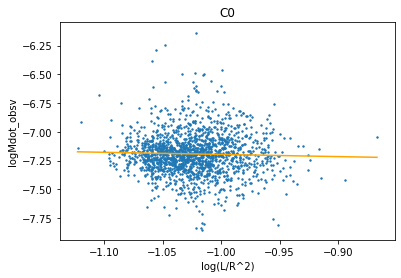

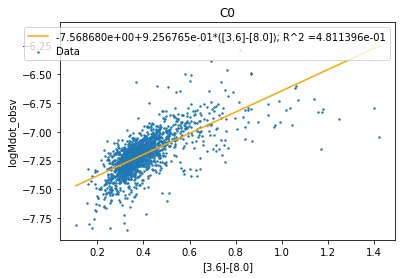

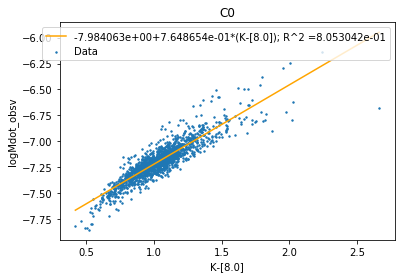

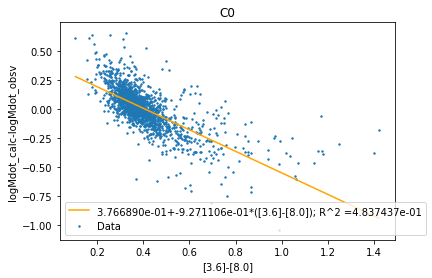

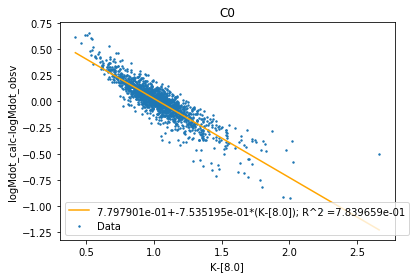

In [48]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/ExtendedAnalyses/log(LdivR^2)/subtract_logR'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_KMinH, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')



 Initial Fit: logMdot= -0.7257152711921853 *x+ -7.737200623531998


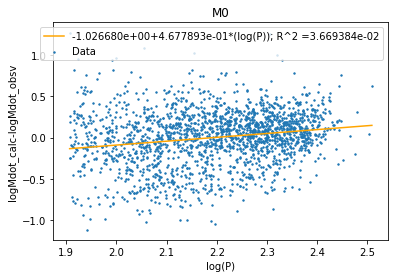


 Corrected Fit: logMdot= 0.8250780839278443 *log(L/R^2)+ 0.4677893424794125 log(P)+ -5.394941711410531


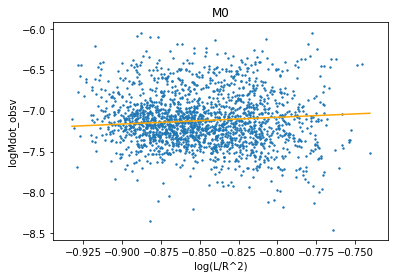

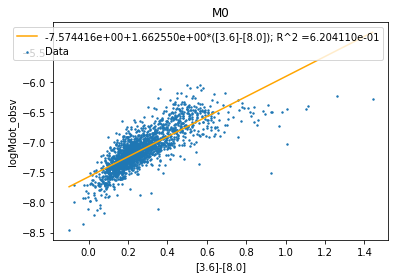

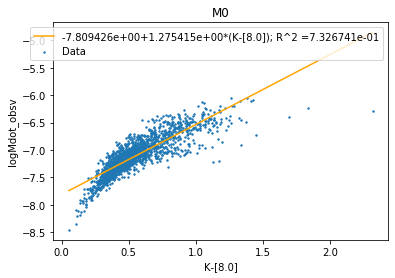

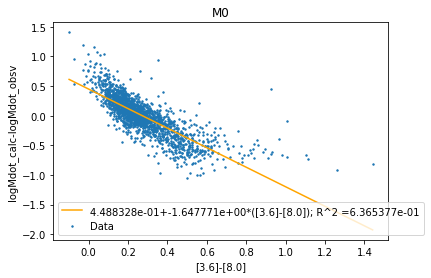

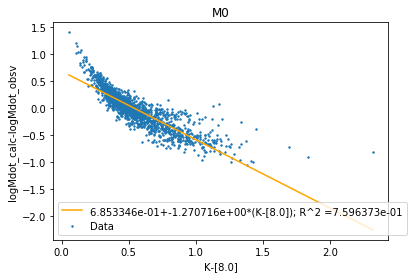


 Initial Fit: logMdot= -4.1836733340187715 *x+ -11.832026633574293


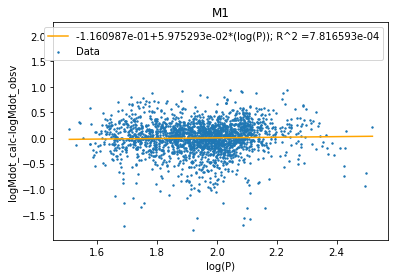


 Corrected Fit: logMdot= -3.9904520877100307 *log(L/R^2)+ 0.05975293089672085 log(P)+ -11.546641472677292


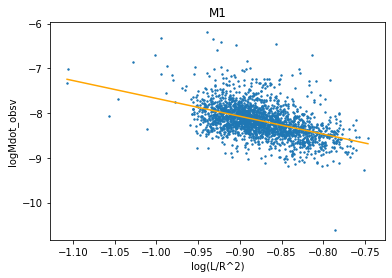

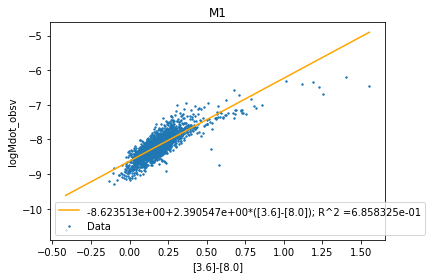

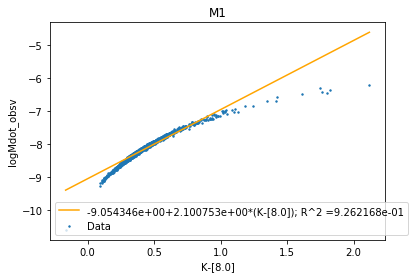

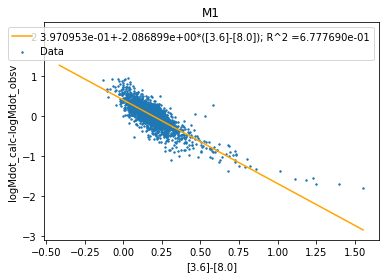

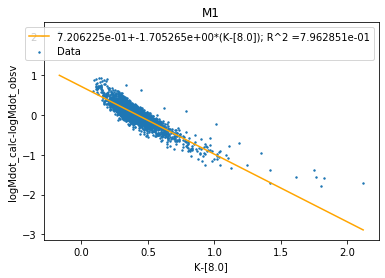


 Initial Fit: logMdot= -0.1600179107615412 *x+ -7.3564225123486615


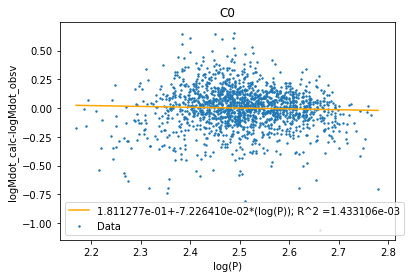


 Corrected Fit: logMdot= -0.29588231785695074 *log(L/R^2)+ -0.07226409658450876 log(P)+ -7.676703530741079


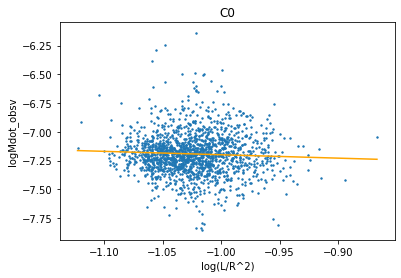

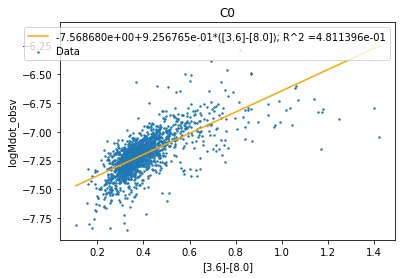

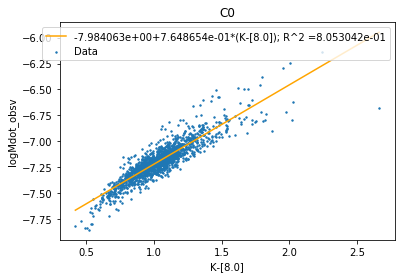

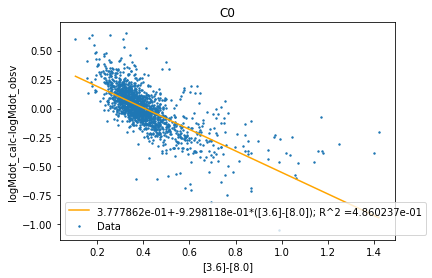

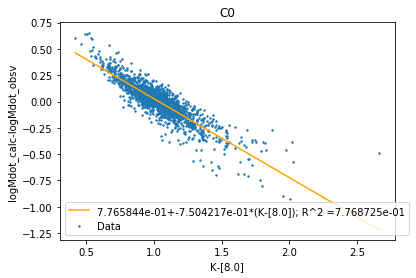

In [49]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/ExtendedAnalyses/log(LdivR^2)/subtract_logP'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_KMinH, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')


 Initial Fit: logMdot= -0.7257152711921853 *x+ -7.737200623531998


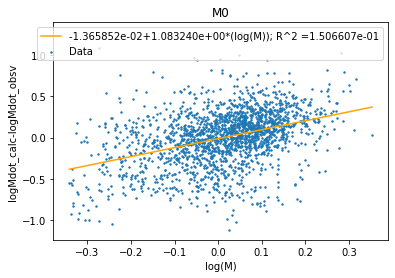


 Corrected Fit: logMdot= -1.4385503474541042 *log(L/R^2)+ 1.0832399260041072 log(M)+ -8.328258879000373


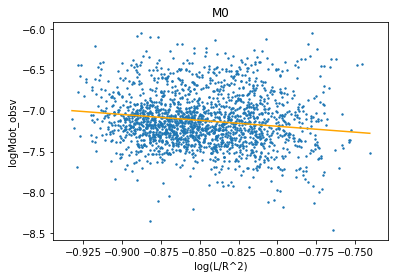

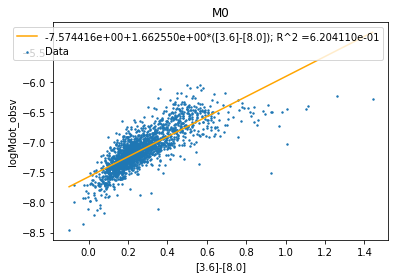

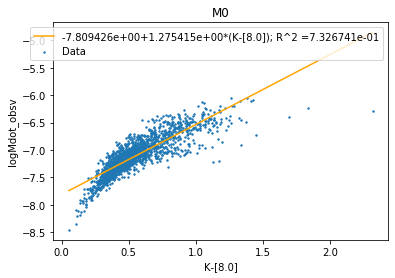

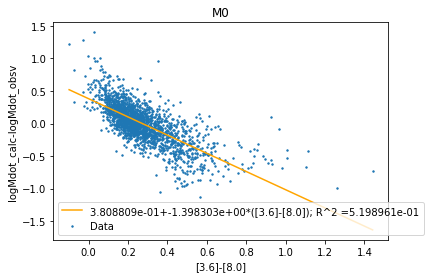

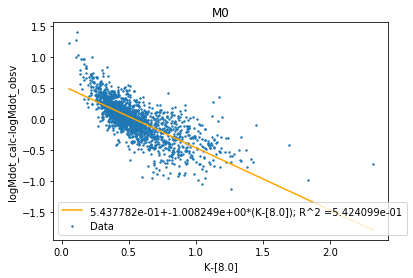


 Initial Fit: logMdot= -4.1836733340187715 *x+ -11.832026633574293


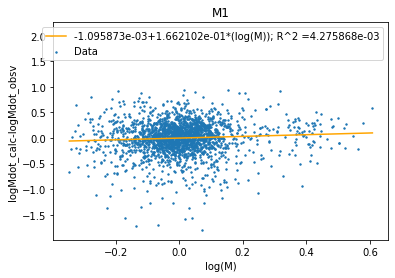


 Corrected Fit: logMdot= -4.058669472015411 *log(L/R^2)+ 0.16621019774293064 log(M)+ -11.721411451503956


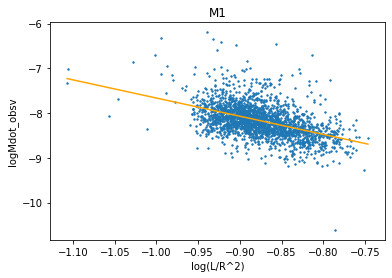

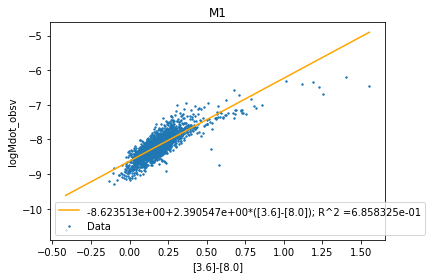

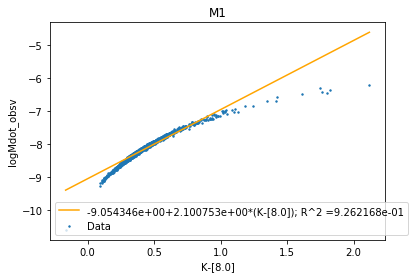

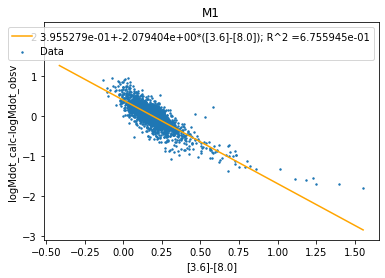

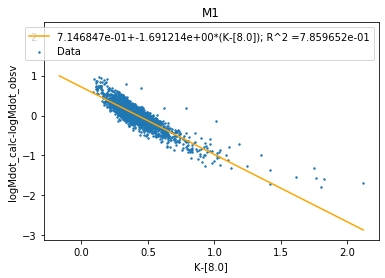


 Initial Fit: logMdot= -0.1600179107615412 *x+ -7.3564225123486615


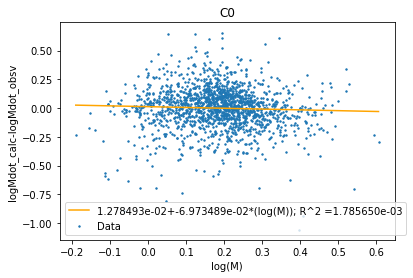


 Corrected Fit: logMdot= -0.04301020607497433 *log(L/R^2)+ -0.06973488997966033 log(M)+ -7.249367274327397


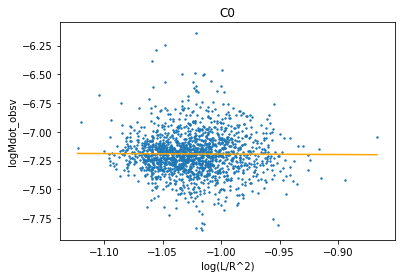

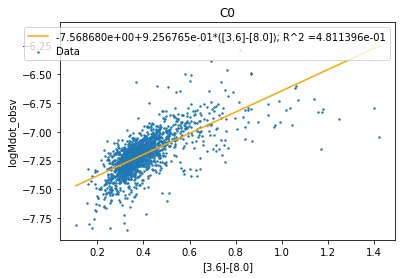

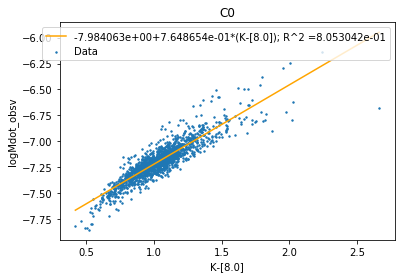

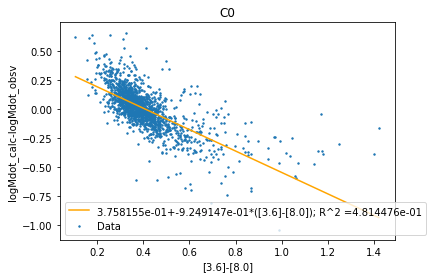

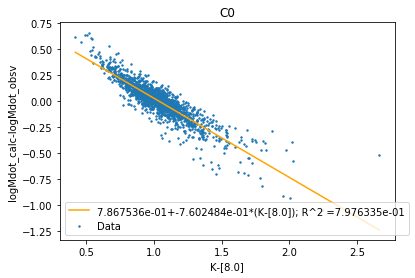

In [50]:
Directory = 'Single_Parameter_Fits/2color_Mdot_Alg/ExtendedAnalyses/log(LdivR^2)/subtract_logM'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_KMinH, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
